In [1]:

# If needed, install dependencies in your environment:
# %pip install pandas numpy scikit-learn statsmodels matplotlib seaborn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, roc_auc_score
)
from IPython.display import display

RANDOM_STATE = 611
TEST_SIZE = 0.30
DATA_URL = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Random state:", RANDOM_STATE)


Random state: 611


In [2]:

df_raw = pd.read_csv(DATA_URL)
print("Raw dataset shape:", df_raw.shape)
display(df_raw.head())

required = [
    "days_b_screening_arrest", "is_recid", "c_charge_degree",
    "score_text", "decile_score", "age", "sex", "race",
    "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"
]
missing_columns = sorted(set(required) - set(df_raw.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

df = df_raw.copy()
df = df[
    df["days_b_screening_arrest"].between(-30, 30, inclusive="both")
    & (df["is_recid"] != -1)
    & (df["c_charge_degree"] != "O")
    & (df["score_text"] != "N/A")
].copy()

df["is_recidivist"] = df["is_recid"].astype(int)
df["decile_score"] = pd.to_numeric(df["decile_score"], errors="coerce")

print("Filtered analysis cohort:", df.shape)
print("Recidivism target distribution:")
display(df["is_recidivist"].value_counts(dropna=False).rename_axis("is_recidivist").to_frame("count"))


Raw dataset shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,juv_fel_count,decile_score,juv_misd_count,juv_other_count,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_case_number,c_offense_date,c_arrest_date,c_days_from_compas,c_charge_degree,c_charge_desc,is_recid,r_case_number,r_charge_degree,r_days_from_arrest,r_offense_date,r_charge_desc,r_jail_in,r_jail_out,violent_recid,is_violent_recid,vr_case_number,vr_charge_degree,vr_offense_date,vr_charge_desc,type_of_assessment,decile_score.1,score_text,screening_date,v_type_of_assessment,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,0,1,0,0,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,13011352CF10A,2013-08-13,NaN,1.0,F,Aggravated Assault w/Firearm,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-08-14,Risk of Violence,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,0,3,0,0,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,13001275CF10A,2013-01-26,NaN,1.0,F,Felony Battery w/Prior Convict,1,13009779CF10A,(F3),NaN,2013-07-05,Felony Battery (Dom Strang),NaN,NaN,NaN,1,13009779CF10A,(F3),2013-07-05,Felony Battery (Dom Strang),Risk of Recidivism,3,Low,2013-01-27,Risk of Violence,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,0,4,0,1,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,13005330CF10A,2013-04-13,NaN,1.0,F,Possession of Cocaine,1,13011511MM10A,(M1),0.0,2013-06-16,Driving Under The Influence,2013-06-16,2013-06-16,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,4,Low,2013-04-14,Risk of Violence,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,0,8,1,0,1,NaN,NaN,NaN,13000570CF10A,2013-01-12,NaN,1.0,F,Possession of Cannabis,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,8,High,2013-01-13,Risk of Violence,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,0,1,0,0,2,NaN,NaN,NaN,12014130CF10A,NaN,2013-01-09,76.0,F,arrest case no charge,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-03-26,Risk of Violence,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


Filtered analysis cohort: (6172, 54)
Recidivism target distribution:


,count
is_recidivist,
0,3182
1,2990


Missing values in selected features before imputation:


,missing_count
age,0
priors_count,0
juv_fel_count,0
juv_misd_count,0
juv_other_count,0
sex,0
race,0
c_charge_degree,0


IQR outlier audit (counts; observations are retained):


,feature,lower_IQR_fence,upper_IQR_fence,outlier_count
0,age,-0.5,67.5,51
1,priors_count,-6.0,10.0,492
2,juv_fel_count,0.0,0.0,208
3,juv_misd_count,0.0,0.0,352
4,juv_other_count,0.0,0.0,461


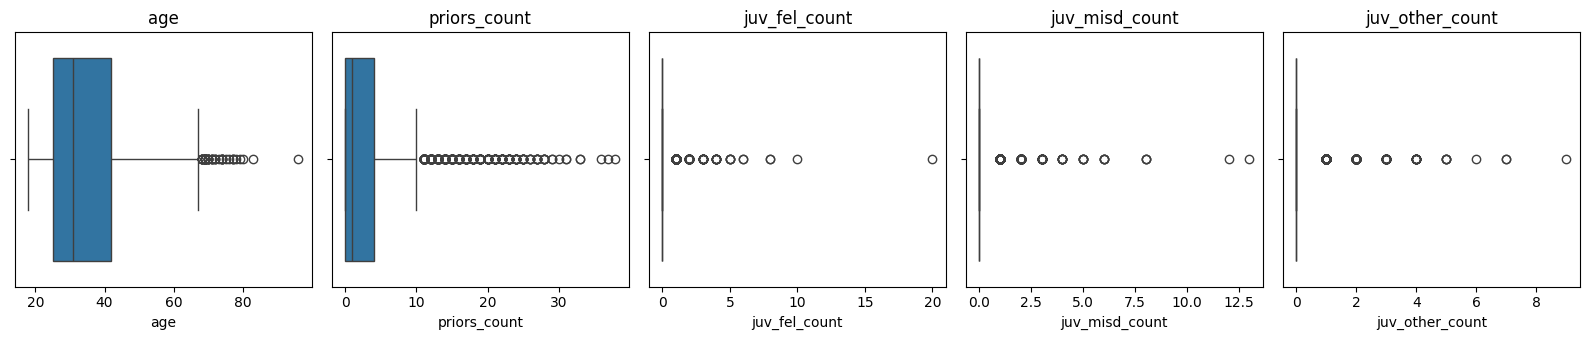

In [3]:

numeric_features = [
    "age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"
]
categorical_features = ["sex", "race", "c_charge_degree"]
feature_columns = numeric_features + categorical_features

# Ensure expected numeric types and remove rows without either assignment target.
for col in numeric_features + ["decile_score", "is_recidivist"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["decile_score", "is_recidivist"]).copy()
df["is_recidivist"] = df["is_recidivist"].astype(int)

print("Missing values in selected features before imputation:")
display(df[feature_columns].isna().sum().to_frame("missing_count"))

print("IQR outlier audit (counts; observations are retained):")
outlier_rows = []
for col in numeric_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "feature": col, "lower_IQR_fence": low, "upper_IQR_fence": high,
        "outlier_count": int(((df[col] < low) | (df[col] > high)).sum())
    })
display(pd.DataFrame(outlier_rows))

fig, axes = plt.subplots(1, len(numeric_features), figsize=(16, 3.5))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [4]:

X = df[feature_columns].copy()
y_linear = df["decile_score"].copy()
y_binary = df["is_recidivist"].copy()

X_train, X_test, yA_train, yA_test, yB_train, yB_test = train_test_split(
    X, y_linear, y_binary,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_binary
)

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocess, numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

print("Training rows:", len(X_train), f"({len(X_train)/len(X):.1%})")
print("Testing rows:", len(X_test), f"({len(X_test)/len(X):.1%})")
print("Train binary outcome rate:", round(yB_train.mean(), 4))
print("Test binary outcome rate:", round(yB_test.mean(), 4))


Training rows: 4320 (70.0%)
Testing rows: 1852 (30.0%)
Train binary outcome rate: 0.4845
Test binary outcome rate: 0.4843


In [5]:

model_A = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
model_B = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=3000, solver="lbfgs"))
])

model_A.fit(X_train, yA_train)
model_B.fit(X_train, yB_train)

pred_A = model_A.predict(X_test)
prob_B = model_B.predict_proba(X_test)[:, 1]

median_A = float(np.median(pred_A))
class_A = (pred_A >= median_A).astype(int)
class_B = (prob_B >= 0.50).astype(int)

agreement_cm = confusion_matrix(class_A, class_B, labels=[0, 1])
mismatch_mask = class_A != class_B
mismatch_count = int(mismatch_mask.sum())
mismatch_pct = 100 * mismatch_count / len(X_test)

print(f"Model A median predicted decile score: {median_A:.4f}")
print("Agreement matrix (rows = Model A low/high; columns = Model B low/high):")
display(pd.DataFrame(
    agreement_cm,
    index=["Model A: low", "Model A: high"],
    columns=["Model B: low", "Model B: high"]
))
print(f"Mismatched classifications: {mismatch_count}/{len(X_test)} ({mismatch_pct:.2f}%)")

display(pd.DataFrame({
    "Model": ["Model A (OLS thresholded at test median)", "Model B (Logistic, threshold 0.50)"],
    "Positive/High classifications": [int(class_A.sum()), int(class_B.sum())],
    "Positive/High rate (%)": [100*class_A.mean(), 100*class_B.mean()]
}))


Model A median predicted decile score: 4.5491
Agreement matrix (rows = Model A low/high; columns = Model B low/high):


,Model B: low,Model B: high
Model A: low,875,49
Model A: high,154,774


Mismatched classifications: 203/1852 (10.96%)


,Model,Positive/High classifications,Positive/High rate (%)
0,Model A (OLS thresholded at test median),928,50.107991
1,"Model B (Logistic, threshold 0.50)",823,44.438445


In [6]:

# Prepare complete analysis rows for statsmodels formula models.
formula_cols = [
    "is_recidivist", "priors_count", "age", "race", "c_charge_degree",
    "juv_fel_count", "juv_misd_count", "juv_other_count", "sex"
]
formula_df = df[formula_cols].copy()
formula_df["race"] = formula_df["race"].fillna("Unknown")
formula_df["c_charge_degree"] = formula_df["c_charge_degree"].fillna("Unknown")
formula_df["sex"] = formula_df["sex"].fillna("Unknown")
for c in ["priors_count", "age", "juv_fel_count", "juv_misd_count", "juv_other_count"]:
    formula_df[c] = formula_df[c].fillna(formula_df[c].median())

simpson_formula = (
    "is_recidivist ~ priors_count + age + C(race) + C(c_charge_degree) "
    "+ juv_fel_count + juv_misd_count + juv_other_count"
)

def fit_glm(formula, data):
    return smf.glm(formula=formula, data=data, family=sm.families.Binomial()).fit()

simpson_models = {"Full cohort": fit_glm(simpson_formula, formula_df)}
for group in ["Female", "Male"]:
    subset = formula_df[formula_df["sex"].str.lower() == group.lower()]
    if len(subset) > 30 and subset["is_recidivist"].nunique() == 2:
        simpson_models[group] = fit_glm(simpson_formula, subset)

simpson_rows = []
for label, fitted in simpson_models.items():
    ci = fitted.conf_int().loc["priors_count"]
    simpson_rows.append({
        "group": label,
        "n": int(fitted.nobs),
        "priors_count_coef": fitted.params["priors_count"],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1],
        "p_value": fitted.pvalues["priors_count"]
    })
simpson_table = pd.DataFrame(simpson_rows)
display(simpson_table)
print("Compare coefficient signs and confidence intervals. Do not label it Simpson's Paradox unless the observed pattern supports that claim.")


,group,n,priors_count_coef,95% CI lower,95% CI upper,p_value
0,Full cohort,6172,0.170866,0.153919,0.187813,6.413996e-87
1,Female,1175,0.237817,0.184650,0.290983,1.834041e-18
2,Male,4997,0.157116,0.139288,0.174944,7.482787e-67


Compare coefficient signs and confidence intervals. Do not label it Simpson's Paradox unless the observed pattern supports that claim.


In [7]:

full_formula = (
    "is_recidivist ~ priors_count + age + juv_fel_count + juv_misd_count "
    "+ juv_other_count + C(sex) + C(race) + C(c_charge_degree)"
)
reduced_formula = (
    "is_recidivist ~ age + juv_fel_count + juv_misd_count "
    "+ juv_other_count + C(sex) + C(race) + C(c_charge_degree)"
)
full_ovb = fit_glm(full_formula, formula_df)
reduced_ovb = fit_glm(reduced_formula, formula_df)

shared_predictors = ["age", "juv_fel_count", "juv_misd_count", "juv_other_count"]
ovb_rows = []
for term in shared_predictors:
    b_full = float(full_ovb.params[term])
    b_reduced = float(reduced_ovb.params[term])
    pct = np.nan if abs(b_full) < 1e-10 else abs(b_reduced - b_full) / abs(b_full) * 100
    ovb_rows.append({
        "predictor": term,
        "full_model_coefficient": b_full,
        "reduced_model_coefficient": b_reduced,
        "absolute_percentage_change": pct
    })
ovb_table = pd.DataFrame(ovb_rows).sort_values("absolute_percentage_change", ascending=False)
display(ovb_table)
print("Omitted variable:", "priors_count")
if ovb_table["absolute_percentage_change"].notna().any():
    print("Largest coefficient shift:", ovb_table.iloc[0]["predictor"])


,predictor,full_model_coefficient,reduced_model_coefficient,absolute_percentage_change
2,juv_misd_count,-0.000518,0.384728,74334.907077
1,juv_fel_count,0.119650,0.478805,300.170832
0,age,-0.043019,-0.026685,37.970391
3,juv_other_count,0.297528,0.406569,36.649142


Omitted variable: priors_count
Largest coefficient shift: juv_misd_count


In [8]:

adversarial_test = X_test.copy()
adversarial_test["actual"] = np.asarray(yB_test)
adversarial_test["predicted_probability"] = prob_B
adversarial_test["predicted_class_050"] = class_B
adversarial_test["error_type"] = np.select(
    [
        (adversarial_test["predicted_probability"] >= 0.75) & (adversarial_test["actual"] == 0),
        (adversarial_test["predicted_probability"] <= 0.25) & (adversarial_test["actual"] == 1)
    ],
    ["False positive (P >= 0.75)", "False negative (P <= 0.25)"],
    default="Not selected"
)

wrong_confident = adversarial_test[adversarial_test["error_type"] != "Not selected"].copy()
wrong_count = len(wrong_confident)
wrong_pct = 100 * wrong_count / len(adversarial_test)
if wrong_count > 50:
    adversarial_subset = wrong_confident.sample(n=50, random_state=RANDOM_STATE)
else:
    adversarial_subset = wrong_confident.copy()

print(f"All high-confidence wrong test predictions: {wrong_count}/{len(adversarial_test)} ({wrong_pct:.2f}%)")
print("Rows retained for adversarial analysis:", len(adversarial_subset))
display(adversarial_subset.head(50))

def demographic_summary(frame, label):
    return pd.DataFrame({
        "dataset": [label],
        "n": [len(frame)],
        "mean_age": [pd.to_numeric(frame["age"], errors="coerce").mean()],
        "median_age": [pd.to_numeric(frame["age"], errors="coerce").median()],
        "female_pct": [(frame["sex"].astype(str).str.lower() == "female").mean() * 100],
        "male_pct": [(frame["sex"].astype(str).str.lower() == "male").mean() * 100],
        "mean_priors_count": [pd.to_numeric(frame["priors_count"], errors="coerce").mean()]
    })

demo_compare = pd.concat([
    demographic_summary(X_test, "Full test set"),
    demographic_summary(adversarial_subset, "Adversarial subset")
], ignore_index=True)
display(demo_compare)

if len(adversarial_subset):
    print("Adversarial subset error-type counts:")
    display(adversarial_subset["error_type"].value_counts().to_frame("count"))
    print("Potential shared characteristics (inspect these; do not assume causation):")
    display(adversarial_subset[["age", "sex", "race", "priors_count", "juv_fel_count",
                                "juv_misd_count", "juv_other_count", "error_type"]].describe(include="all"))
else:
    print("No cases met the high-confidence error criteria on this split.")


All high-confidence wrong test predictions: 90/1852 (4.86%)
Rows retained for adversarial analysis: 50


,age,priors_count,juv_fel_count,juv_misd_count,juv_other_count,sex,race,c_charge_degree,actual,predicted_probability,predicted_class_050,error_type
5603,58,0,0,0,0,Male,African-American,F,1,0.190481,0,False negative (P <= 0.25)
1780,60,0,0,0,0,Female,Caucasian,F,1,0.120355,0,False negative (P <= 0.25)
1995,32,8,0,0,1,Male,African-American,F,0,0.787769,1,False positive (P >= 0.75)
5678,55,1,0,0,0,Male,Caucasian,F,1,0.215707,0,False negative (P <= 0.25)
3479,58,1,0,0,0,Male,Caucasian,F,1,0.194119,0,False negative (P <= 0.25)
3009,52,0,0,0,0,Male,African-American,M,1,0.205669,0,False negative (P <= 0.25)
2897,53,1,0,0,0,Male,Caucasian,M,1,0.202295,0,False negative (P <= 0.25)
6485,35,9,0,0,0,Male,African-American,F,0,0.755475,1,False positive (P >= 0.75)
4872,52,0,0,0,0,Male,African-American,F,1,0.234750,0,False negative (P <= 0.25)
4567,59,1,0,0,0,Male,Hispanic,F,1,0.158278,0,False negative (P <= 0.25)


,dataset,n,mean_age,median_age,female_pct,male_pct,mean_priors_count
0,Full test set,1852,34.241901,31.0,19.384449,80.615551,3.220302
1,Adversarial subset,50,47.880000,51.0,18.000000,82.000000,5.400000


Adversarial subset error-type counts:


,count
error_type,
False negative (P <= 0.25),31
False positive (P >= 0.75),19


Potential shared characteristics (inspect these; do not assume causation):


,age,sex,race,priors_count,juv_fel_count,juv_misd_count,juv_other_count,error_type
count,50.000000,50,50,50.000000,50.000000,50.000000,50.000000,50
unique,NaN,2,4,NaN,NaN,NaN,NaN,2
top,NaN,Male,African-American,NaN,NaN,NaN,NaN,False negative (P <= 0.25)
freq,NaN,41,22,NaN,NaN,NaN,NaN,31
mean,47.880000,NaN,NaN,5.400000,0.080000,0.080000,0.180000,NaN
std,14.757413,NaN,NaN,7.065293,0.340468,0.274048,0.595562,NaN
min,22.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN
25%,35.250000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN
50%,51.000000,NaN,NaN,1.500000,0.000000,0.000000,0.000000,NaN
75%,56.750000,NaN,NaN,11.250000,0.000000,0.000000,0.000000,NaN


Fairness comparison groups: A = Black; B = Caucasian
Group counts in test set:


,n
group,
B,657


,threshold,DP_ratio_A_over_B,EO_min_TPR_FPR_ratio,PP_ratio_A_over_B,A_positive_rate,B_positive_rate,A_TPR,B_TPR,A_FPR,B_FPR,A_PPV,B_PPV,A_n,B_n
0,0.05,NaN,NaN,NaN,NaN,1.0000,NaN,1.0000,NaN,1.0000,NaN,0.4368,0,657
1,0.15,NaN,NaN,NaN,NaN,0.9376,NaN,0.9721,NaN,0.9108,NaN,0.4529,0,657
2,0.25,NaN,NaN,NaN,NaN,0.7900,NaN,0.9059,NaN,0.7000,NaN,0.5010,0,657
3,0.35,NaN,NaN,NaN,NaN,0.6225,NaN,0.7840,NaN,0.4973,NaN,0.5501,0,657
4,0.45,NaN,NaN,NaN,NaN,0.4064,NaN,0.5854,NaN,0.2676,NaN,0.6292,0,657
5,0.55,NaN,NaN,NaN,NaN,0.2009,NaN,0.3519,NaN,0.0838,NaN,0.7652,0,657
6,0.65,NaN,NaN,NaN,NaN,0.1050,NaN,0.1986,NaN,0.0324,NaN,0.8261,0,657
7,0.75,NaN,NaN,NaN,NaN,0.0594,NaN,0.1150,NaN,0.0162,NaN,0.8462,0,657
8,0.85,NaN,NaN,NaN,NaN,0.0259,NaN,0.0523,NaN,0.0054,NaN,0.8824,0,657
9,0.95,NaN,NaN,NaN,NaN,0.0107,NaN,0.0209,NaN,0.0027,NaN,0.8571,0,657


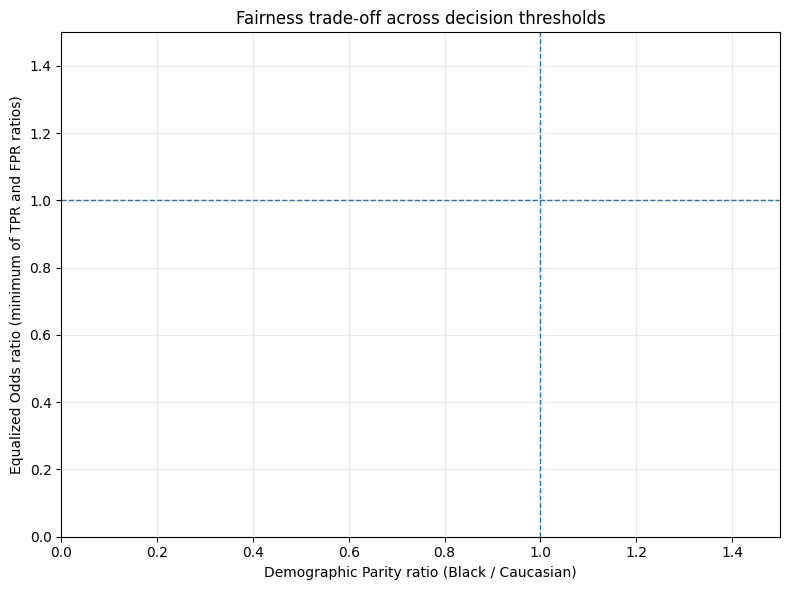

In [9]:

fair = X_test.copy()
fair["actual"] = np.asarray(yB_test)
fair["probability"] = prob_B
fair["race_clean"] = fair["race"].astype(str).str.strip().str.lower()

group_A_name, group_B_name = "black", "caucasian"
fair = fair[fair["race_clean"].isin([group_A_name, group_B_name])].copy()
fair["group"] = np.where(fair["race_clean"] == group_A_name, "A", "B")

def safe_ratio(a, b):
    return np.nan if (pd.isna(a) or pd.isna(b) or b == 0) else a / b

def group_rates(part, threshold):
    y = part["actual"].to_numpy(dtype=int)
    pred = (part["probability"].to_numpy() >= threshold).astype(int)
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    tn = np.sum((pred == 0) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    tpr = tp / (tp + fn) if (tp + fn) else np.nan
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    dp = pred.mean() if len(pred) else np.nan
    ppv = tp / (tp + fp) if (tp + fp) else np.nan
    return {"DP_rate": dp, "TPR": tpr, "FPR": fpr, "PPV": ppv, "n": len(part)}

fair_rows = []
for threshold in np.round(np.arange(0.05, 0.951, 0.10), 2):
    a = group_rates(fair[fair["group"] == "A"], threshold)
    b = group_rates(fair[fair["group"] == "B"], threshold)
    eo_tpr = safe_ratio(a["TPR"], b["TPR"])
    eo_fpr = safe_ratio(a["FPR"], b["FPR"])
    eo = np.nan if pd.isna(eo_tpr) or pd.isna(eo_fpr) else min(eo_tpr, eo_fpr)
    fair_rows.append({
        "threshold": threshold,
        "DP_ratio_A_over_B": safe_ratio(a["DP_rate"], b["DP_rate"]),
        "EO_min_TPR_FPR_ratio": eo,
        "PP_ratio_A_over_B": safe_ratio(a["PPV"], b["PPV"]),
        "A_positive_rate": a["DP_rate"], "B_positive_rate": b["DP_rate"],
        "A_TPR": a["TPR"], "B_TPR": b["TPR"],
        "A_FPR": a["FPR"], "B_FPR": b["FPR"],
        "A_PPV": a["PPV"], "B_PPV": b["PPV"],
        "A_n": a["n"], "B_n": b["n"]
    })

fairness_table = pd.DataFrame(fair_rows)
print("Fairness comparison groups: A = Black; B = Caucasian")
print("Group counts in test set:")
display(fair["group"].value_counts().rename_axis("group").to_frame("n"))
display(fairness_table.round(4))

plt.figure(figsize=(8, 6))
plt.scatter(fairness_table["DP_ratio_A_over_B"], fairness_table["EO_min_TPR_FPR_ratio"])
for _, row in fairness_table.iterrows():
    if pd.notna(row["DP_ratio_A_over_B"]) and pd.notna(row["EO_min_TPR_FPR_ratio"]):
        plt.annotate(f't={row["threshold"]:.2f}',
                     (row["DP_ratio_A_over_B"], row["EO_min_TPR_FPR_ratio"]),
                     xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.axvline(1.0, linestyle="--", linewidth=1)
plt.axhline(1.0, linestyle="--", linewidth=1)
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (Black / Caucasian)")
plt.ylabel("Equalized Odds ratio (minimum of TPR and FPR ratios)")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("fairness_tradeoff.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:

agreement_df = pd.DataFrame(
    agreement_cm,
    index=["Model A low", "Model A high"],
    columns=["Model B low", "Model B high"]
)
agreement_df.to_csv("part1_agreement_matrix.csv")
simpson_table.to_csv("part2_1_simpson_coefficients.csv", index=False)
ovb_table.to_csv("part2_2_omitted_variable_bias.csv", index=False)
adversarial_subset.to_csv("part2_3_adversarial_subset.csv", index=True)
demo_compare.to_csv("part2_3_demographic_comparison.csv", index=False)
fairness_table.to_csv("part2_4_fairness_metrics.csv", index=False)

print("Saved:")
for filename in [
    "part1_agreement_matrix.csv",
    "part2_1_simpson_coefficients.csv",
    "part2_2_omitted_variable_bias.csv",
    "part2_3_adversarial_subset.csv",
    "part2_3_demographic_comparison.csv",
    "part2_4_fairness_metrics.csv",
    "fairness_tradeoff.png"
]:
    print(" -", filename)


Saved:
 - part1_agreement_matrix.csv
 - part2_1_simpson_coefficients.csv
 - part2_2_omitted_variable_bias.csv
 - part2_3_adversarial_subset.csv
 - part2_3_demographic_comparison.csv
 - part2_4_fairness_metrics.csv
 - fairness_tradeoff.png
